Cross Validation 

Dataset: `california_housing.csv`

Target prediksi: `MedHouseVal` | nilai median rumah pada blok sensus, dalam satuan dataset (puluhan/ratusan ribu dolar; nilai target dibatasi pada dataset asli).

Import Library

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, cross_val_predict, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

RANDOM_STATE = 72018

1. Load dataset

In [2]:
df = pd.read_csv("data/california_housing.csv")

print("Shape:", df.shape)
display(df.head())

Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [4]:
display(df.isna().sum().to_frame("missing_values"))
display(df.describe().T)

,missing_values
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


Dataset ini memiliki fitur numerik seperti `MedInc`, `HouseAge`, `AveRooms`, `AveBedrms`, `Population`, `AveOccup`, `Latitude`, dan `Longitude`. Kolom `MedHouseVal` menjadi target yang akan diprediksi.

Kita tidak menggunakan `MedHouseVal` sebagai fitur karena itu akan membocorkan jawaban ke model.

In [5]:
target = "MedHouseVal"
X = df.drop(columns=[target])
y = df[target]

print("Jumlah baris:", len(df))
print("Jumlah fitur:", X.shape[1])
print("Target:", target)

Jumlah baris: 20640
Jumlah fitur: 8
Target: MedHouseVal


2. Cross-validation dengan KFold

`KFold` membagi dataset menjadi beberapa fold. Pada setiap putaran, satu fold digunakan untuk validasi dan fold lain digunakan untuk melatih model. Dengan begitu, setiap baris mendapat giliran menjadi data validasi.

In [6]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for fold, (train_index, test_index) in enumerate(kf.split(X), start=1):
    print(f"Fold {fold}: train={len(train_index):,} baris, validation={len(test_index):,} baris")

Fold 1: train=16,512 baris, validation=4,128 baris
Fold 2: train=16,512 baris, validation=4,128 baris
Fold 3: train=16,512 baris, validation=4,128 baris
Fold 4: train=16,512 baris, validation=4,128 baris
Fold 5: train=16,512 baris, validation=4,128 baris


3. Evaluasi Linear Regression secara manual

Kita akan melatih model pada setiap fold dan mengumpulkan metrik validasi. RMSE dan MAE lebih kecil biasanya lebih baik, sedangkan \(R^2\) yang lebih tinggi biasanya lebih baik.

In [7]:
fold_results = []
model = LinearRegression()

for fold, (train_index, test_index) in enumerate(kf.split(X), start=1):
    X_train, X_valid = X.iloc[train_index], X.iloc[test_index]
    y_train, y_valid = y.iloc[train_index], y.iloc[test_index]

    model.fit(X_train, y_train)
    pred = model.predict(X_valid)

    fold_results.append({
        "fold": fold,
        "RMSE": np.sqrt(mean_squared_error(y_valid, pred)),
        "MAE": mean_absolute_error(y_valid, pred),
        "R2": r2_score(y_valid, pred)
    })

fold_results = pd.DataFrame(fold_results)
display(fold_results)
display(fold_results[["RMSE", "MAE", "R2"]].agg(["mean", "std"]))

,fold,RMSE,MAE,R2
0,1,0.705493,0.525076,0.624028
1,2,0.738991,0.541135,0.604988
2,3,0.730007,0.525368,0.584276
3,4,0.731197,0.534187,0.604764
4,5,0.722389,0.530967,0.603537


,RMSE,MAE,R2
mean,0.725615,0.531347,0.604318
std,0.012695,0.006691,0.014066


4. Menggunakan Pipeline dan cross_val_predict

`Pipeline` menggabungkan langkah preprocessing dan model menjadi satu objek. Scaling dilakukan di dalam setiap fold, sehingga scaler hanya mempelajari statistik dari data training fold dan mengurangi risiko data leakage.

`cross_val_predict` menghasilkan prediksi out-of-fold untuk setiap baris.

In [8]:
linear_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("regression", LinearRegression())
])

oof_predictions = cross_val_predict(linear_pipeline, X, y, cv=kf, n_jobs=-1)

print("OOF RMSE:", np.sqrt(mean_squared_error(y, oof_predictions)))
print("OOF MAE :", mean_absolute_error(y, oof_predictions))
print("OOF R2  :", r2_score(y, oof_predictions))

OOF RMSE: 0.725704239080306
OOF MAE : 0.5313466505196432
OOF R2  : 0.6044861072189538


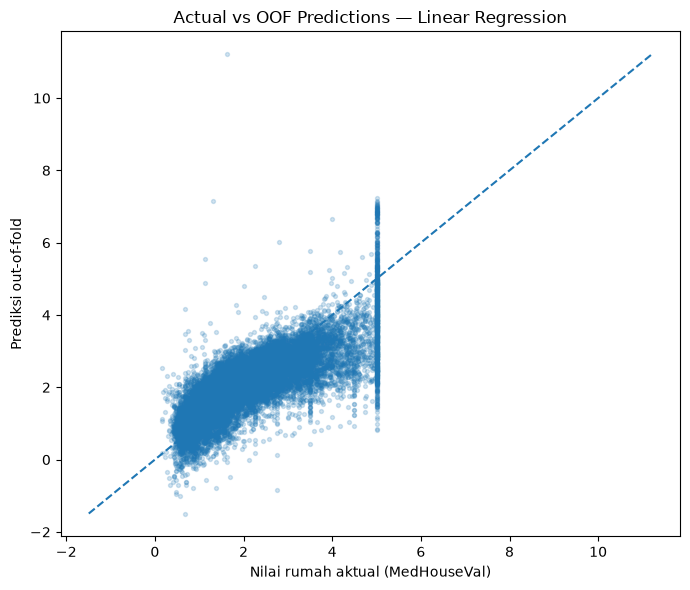

In [9]:
plt.figure(figsize=(7, 6))
plt.scatter(y, oof_predictions, alpha=0.2, s=8)
lims = [min(y.min(), oof_predictions.min()), max(y.max(), oof_predictions.max())]
plt.plot(lims, lims, "--")
plt.xlabel("Nilai rumah aktual (MedHouseVal)")
plt.ylabel("Prediksi out-of-fold")
plt.title("Actual vs OOF Predictions — Linear Regression")
plt.tight_layout()
plt.show()

5. Hyperparameter tuning: Lasso

Lasso menggunakan regularisasi L1. Parameter `alpha` mengatur kekuatan regularisasi. Kita menguji beberapa nilai `alpha` dan membandingkan skor cross-validation.

Karena dataset cukup besar, bagian ini menggunakan fitur asli terlebih dahulu agar komputasi tetap praktis.

In [10]:
alphas = np.logspace(-3, 1, 9)
lasso_results = []

for alpha in alphas:
    estimator = Pipeline([
        ("scaler", StandardScaler()),
        ("lasso", Lasso(alpha=alpha, max_iter=20000))
    ])
    scores = cross_validate(
        estimator, X, y, cv=kf,
        scoring={"r2": "r2", "neg_rmse": "neg_root_mean_squared_error"},
        n_jobs=-1
    )
    lasso_results.append({
        "alpha": alpha,
        "mean_R2": scores["test_r2"].mean(),
        "mean_RMSE": -scores["test_neg_rmse"].mean()
    })

lasso_results = pd.DataFrame(lasso_results)
display(lasso_results)

,alpha,mean_R2,mean_RMSE
0,0.001000,0.604382,0.725567
1,0.003162,0.604242,0.725715
2,0.010000,0.601201,0.728545
3,0.031623,0.575520,0.751655
4,0.100000,0.493438,0.821101
5,0.316228,0.398124,0.895061
6,1.000000,-0.000129,1.153860
7,3.162278,-0.000129,1.153860
8,10.000000,-0.000129,1.153860


In [11]:
best_lasso_row = lasso_results.loc[lasso_results["mean_R2"].idxmax()]
print("Alpha Lasso terbaik:", best_lasso_row["alpha"])
print("Mean CV R2:", best_lasso_row["mean_R2"])

Alpha Lasso terbaik: 0.001
Mean CV R2: 0.6043823212806302


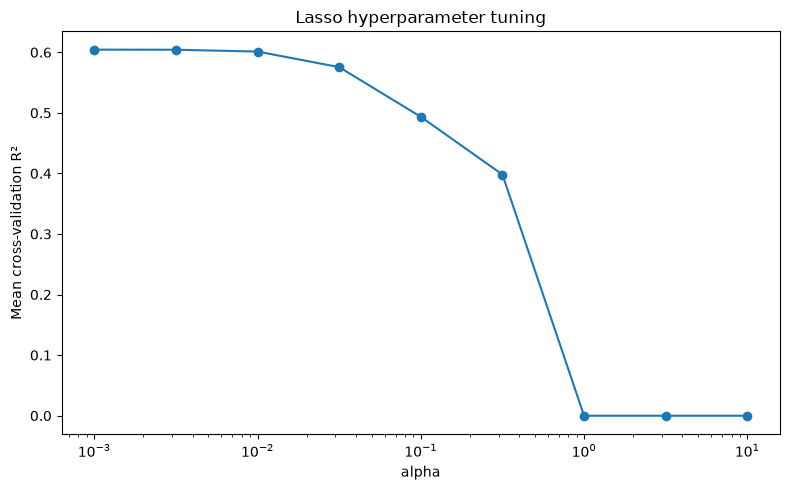

In [12]:
plt.figure(figsize=(8, 5))
plt.semilogx(lasso_results["alpha"], lasso_results["mean_R2"], "-o")
plt.xlabel("alpha")
plt.ylabel("Mean cross-validation R²")
plt.title("Lasso hyperparameter tuning")
plt.tight_layout()
plt.show()

6. Hyperparameter tuning: Ridge

Ridge menggunakan regularisasi L2. Gunakan prosedur cross-validation yang sama agar perbandingan dengan Lasso lebih adil.

In [13]:
ridge_results = []

for alpha in alphas:
    estimator = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=alpha))
    ])
    scores = cross_validate(
        estimator, X, y, cv=kf,
        scoring={"r2": "r2", "neg_rmse": "neg_root_mean_squared_error"},
        n_jobs=-1
    )
    ridge_results.append({
        "alpha": alpha,
        "mean_R2": scores["test_r2"].mean(),
        "mean_RMSE": -scores["test_neg_rmse"].mean()
    })

ridge_results = pd.DataFrame(ridge_results)
display(ridge_results)

,alpha,mean_R2,mean_RMSE
0,0.001000,0.604318,0.725615
1,0.003162,0.604318,0.725615
2,0.010000,0.604318,0.725615
3,0.031623,0.604319,0.725615
4,0.100000,0.604319,0.725615
5,0.316228,0.604319,0.725615
6,1.000000,0.604321,0.725613
7,3.162278,0.604327,0.725609
8,10.000000,0.604340,0.725598


In [14]:
best_ridge_row = ridge_results.loc[ridge_results["mean_R2"].idxmax()]
print("Alpha Ridge terbaik:", best_ridge_row["alpha"])
print("Mean CV R2:", best_ridge_row["mean_R2"])

Alpha Ridge terbaik: 10.0
Mean CV R2: 0.604339653989485


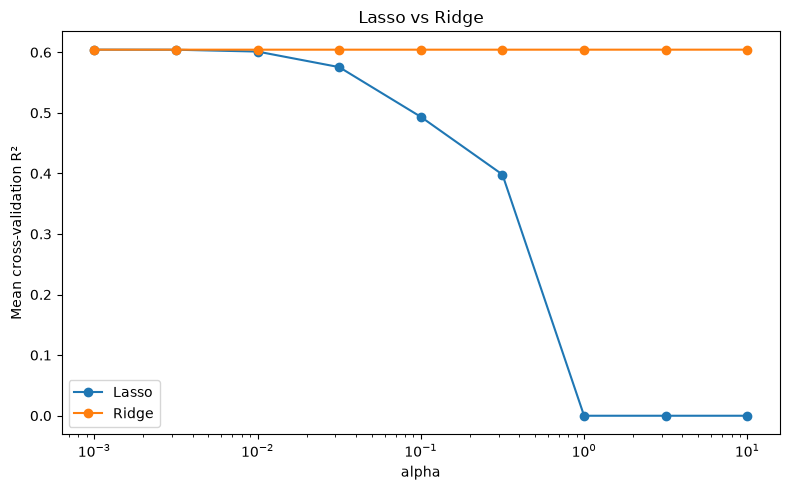

In [15]:
plt.figure(figsize=(8, 5))
plt.semilogx(lasso_results["alpha"], lasso_results["mean_R2"], "-o", label="Lasso")
plt.semilogx(ridge_results["alpha"], ridge_results["mean_R2"], "-o", label="Ridge")
plt.xlabel("alpha")
plt.ylabel("Mean cross-validation R²")
plt.title("Lasso vs Ridge")
plt.legend()
plt.tight_layout()
plt.show()

7. Polynomial features + Ridge

Fitur polinomial dapat menangkap hubungan non-linear sederhana. Kita menggunakan `degree=2` (bukan degree 3) agar jumlah fitur dan waktu komputasi tetap terkendali. Semua langkah berada dalam `Pipeline`, sehingga preprocessing di-fit di dalam fold.

Catatan: fitur polinomial dapat meningkatkan kompleksitas model dan tidak selalu meningkatkan hasil validasi.

In [16]:
poly_ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(include_bias=False)),
    ("poly_scaler", StandardScaler()),
    ("ridge", Ridge())
])

param_grid = {
    "poly__degree": [1, 2],
    "ridge__alpha": [0.1, 1.0, 10.0, 100.0]
}

grid = GridSearchCV(
    poly_ridge,
    param_grid=param_grid,
    cv=kf,
    scoring="r2",
    n_jobs=-1,
    return_train_score=True
)
grid.fit(X, y)

print("Best CV R²:", grid.best_score_)
print("Best parameters:", grid.best_params_)

Best CV R²: 0.6477874389005104
Best parameters: {'poly__degree': 2, 'ridge__alpha': 100.0}


In [17]:
grid_results = pd.DataFrame(grid.cv_results_).sort_values("rank_test_score")
display(grid_results[[
    "param_poly__degree", "param_ridge__alpha",
    "mean_test_score", "std_test_score", "rank_test_score"
]].head(10))

,param_poly__degree,param_ridge__alpha,mean_test_score,std_test_score,rank_test_score
7,2,100.0,0.647787,0.035509,1
2,1,10.0,0.604340,0.012504,2
1,1,1.0,0.604321,0.012573,3
0,1,0.1,0.604319,0.012580,4
3,1,100.0,0.603986,0.011901,5
6,2,10.0,0.500049,0.295565,6
5,2,1.0,0.350948,0.365454,7
4,2,0.1,0.294857,0.407715,8


8. Fit model terbaik dan lihat koefisien

Setelah hyperparameter dipilih menggunakan cross-validation, `GridSearchCV` telah melakukan fit ulang estimator terbaik pada seluruh data yang diberikan ke `grid.fit`. Koefisien berada pada skala fitur setelah preprocessing, sehingga interpretasinya perlu hati-hati.

In [18]:
best_model = grid.best_estimator_
ridge_model = best_model.named_steps["ridge"]
poly = best_model.named_steps["poly"]

feature_names = poly.get_feature_names_out(X.columns)
coef_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": ridge_model.coef_
})
display(coef_df.reindex(coef_df["coefficient"].abs().sort_values(ascending=False).index).head(20))

,feature,coefficient
6,Latitude,-1.077402
7,Longitude,-1.001299
0,MedInc,0.938097
5,AveOccup,-0.893896
3,AveBedrms,0.522427
35,Population AveOccup,0.471885
38,AveOccup^2,0.430255
26,AveRooms AveOccup,0.427154
2,AveRooms,-0.403603
14,MedInc Latitude,-0.393164


Sumber Dataset

Mendeley Data - California Housing Dataset

Simpan file sebagai `data/california_housing.csv` sebelum menjalankan notebook.